[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/BMED365-2027/blob/main/Lab4-Comp-Imag/Kiwi-challenge/notebooks/01-kiwi-explore.ipynb)

*BMED365 — Computational Imaging, Modeling and AI in Biomedicine (Spring 2027)*  
*Updated by Arvid Lundervold — runs locally with `uv` (`bmed365-2027` kernel) or in Google Colab (originally from BMED360, 2019)*

> **Kiwi Challenge Notebook Trilogy (`Lab4-Comp-Imag/Kiwi-challenge`):**
> 1. **`01-kiwi-explore.ipynb` (this notebook)** — 3D NIfTI/DICOM headers, voxel geometry & coordinate systems
> 2. `02-kiwi-seeds-explore.ipynb` — 2D single-slice filtering, thresholding, unsupervised K-means & the Dagstuhl/CUHK 3D variational milestone
> 3. `03-kiwi-paradigms-and-verification.ipynb` — Full 3D segmentation ladder, quantitative "lesion load", & the **4-Panel Semi-Verifiability Dashboard**

# Kiwi MRI — Explore 3D Data, Voxel Geometry & Coordinate Systems

The 3D dataset, consisting of 128 transaxial slices through the long axis of
the kiwifruit, was acquired with the preclinical **7 T Bruker Pharmascan** MRI scanner at the
MIC / Vivarium, University of Bergen, using the 2D RARE pulse sequence
(`Echo Train Length = 8`, `TR = 18,520.8 ms`, `TE = 63.9 ms`, `No. of Averages = 2`,
`Flip Angle = 180°`, `Slice thickness = 0.5 mm`, `In-plane pixel resolution = 0.2344 × 0.2344 mm²`,
`Acquisition matrix = 256 × 256`, `Number of slices = 128`).

### Import libraries & set up local / Colab file helper

In [1]:
%matplotlib inline
# Display figures inline in Jupyter / Google Colab

import os
import pathlib
import tempfile
import urllib.request
import warnings
import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt
import seaborn as sns
import skimage
from PIL import Image as PilImage
from IPython.display import Image, display

try:
    import nibabel as nib
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "nibabel"])
    import nibabel as nib

GITHUB_RAW_BASE = "https://raw.githubusercontent.com/arvidl/BMED365-2027/main/Lab4-Comp-Imag/Kiwi-challenge"

def resolve_kiwi_file(rel_path: str) -> pathlib.Path:
    """Locate an asset or data file locally, or download it automatically in Google Colab."""
    candidates = [
        pathlib.Path("..") / rel_path,
        pathlib.Path("Lab4-Comp-Imag/Kiwi-challenge") / rel_path,
        pathlib.Path(rel_path),
    ]
    for p in candidates:
        if p.exists():
            return p
    dst = pathlib.Path(rel_path)
    dst.parent.mkdir(parents=True, exist_ok=True)
    url = f"{GITHUB_RAW_BASE}/{rel_path}"
    print(f"Downloading {rel_path} from GitHub for Colab session...")
    urllib.request.urlretrieve(url, dst)
    return dst

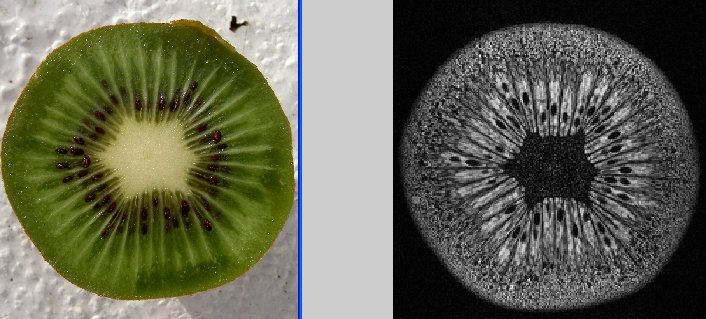

In [2]:
photo_path = resolve_kiwi_file("assets/kiwi_photo_mri_20050219.jpg")
Image(filename=str(photo_path), width=600)

**Image information is 3D SPATIAL** — below is a 3D volume rendering of the scan (originally created at the Visualization Group, Department of Informatics, UiB):

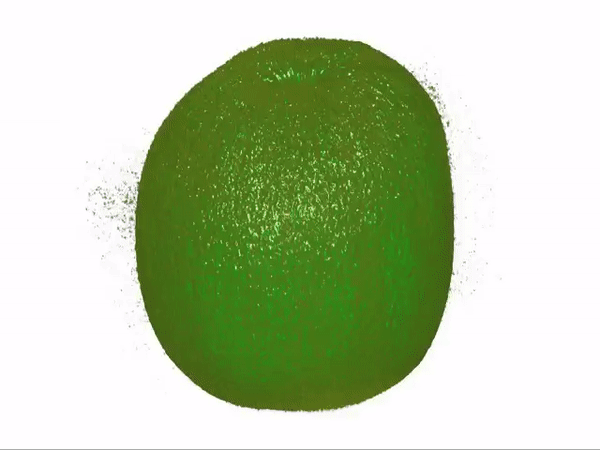

In [3]:
# Resize the 16 MB PNG preview in-memory so the notebook stays lightweight (< 1 MB)
vis_path = resolve_kiwi_file("assets/kiwi-stian-eikeland-vis-video-to-gif.png")
vis_img = PilImage.open(vis_path)
vis_img.thumbnail((640, 640))
display(vis_img)

### Load the 3D NIfTI volume and inspect its header

In [4]:
img_name = "kiwi_20050217191129_131073_RARE_high_res_axial"
fn = str(resolve_kiwi_file(f"data/{img_name}.nii.gz"))
fn

'../data/kiwi_20050217191129_131073_RARE_high_res_axial.nii.gz'

In [5]:
img = nib.load(fn)
img.get_filename()

'../data/kiwi_20050217191129_131073_RARE_high_res_axial.nii.gz'

In [6]:
print("shape of image =", img.header.get_data_shape())
print("units          =", img.header.get_xyzt_units())
print("voxel size     =", img.header.get_zooms())
print("dtype          =", img.header.get_data_dtype())

data = img.get_fdata()
print("data shape     =", data.shape)
print("min            = %d" % data.min())
print("max            = %d" % data.max())
print("number of slices =", img.shape[-1])

shape of image = (256, 256, 128)
units          = ('mm', 'sec')
voxel size     = (np.float32(0.234375), np.float32(0.234375), np.float32(0.5))
dtype          = int16
data shape     = (256, 256, 128)
min            = 71
max            = 32766
number of slices = 128


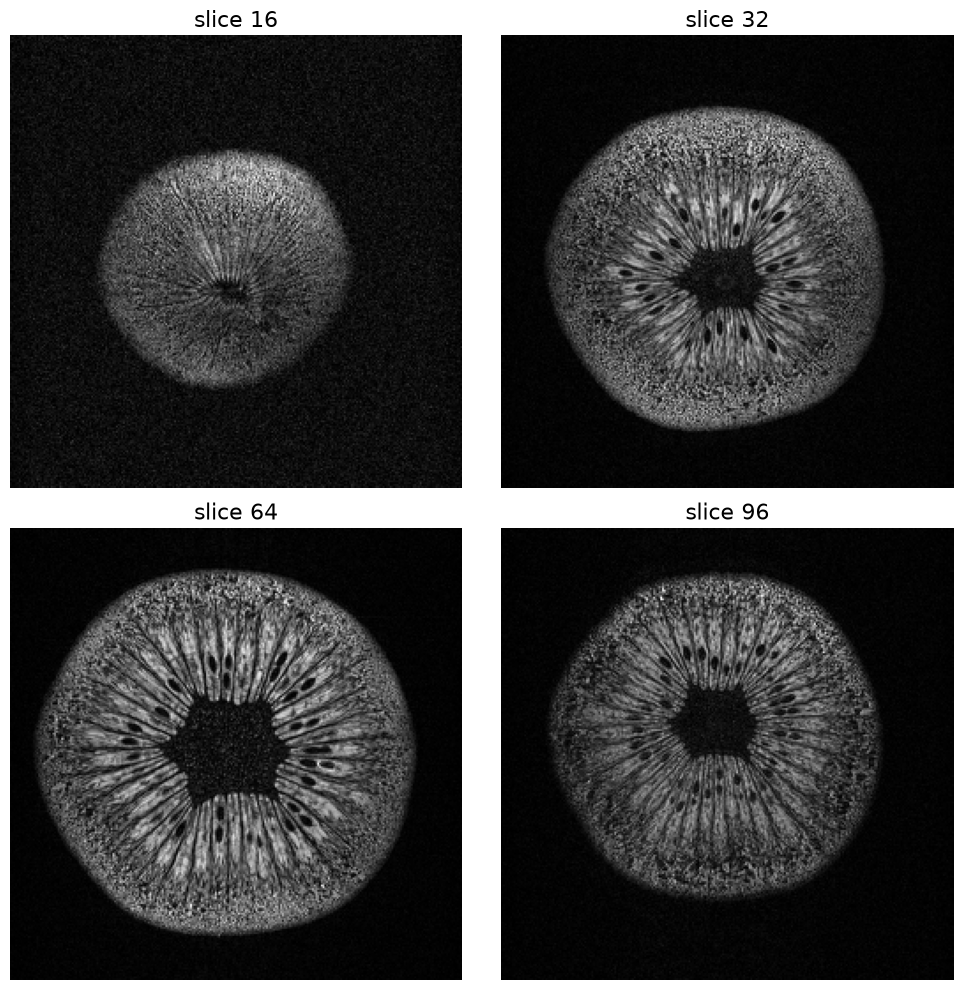

In [7]:
s = [16, 32, 64, 96]
fig = plt.figure("Showing the kiwi image", figsize=[10, 10])
for idx, sl_idx in enumerate(s, start=1):
    plt.subplot(2, 2, idx).set_axis_off()
    plt.title(f"slice {sl_idx}", fontsize=16)
    plt.imshow(data[:, :, sl_idx].T, cmap="gray", origin="lower")  # .T for transpose to standard orientation
plt.tight_layout()
plt.show()

> **CHECK:**
>
> - *Coordinate systems and affine transforms in medical imaging (e.g. [nibabel coordinate systems](https://nipy.org/nibabel/coordinate_systems.html) and [nilearn affine transformations](https://nilearn.github.io/stable/auto_examples/04_manipulating_images/plot_affine_transformation.html))*
> - *Converting from DICOM format (provided by the scanner) to NIfTI format for processing (e.g. [dcm2niix](https://github.com/rordenlab/dcm2niix))*

In [8]:
aff = img.affine
print("affine header:\n", aff)

affine header:
 [[ -0.234375   0.        -0.        27.      ]
 [ -0.         0.234375  -0.       -26.265625]
 [  0.         0.         0.5      -30.75    ]
 [  0.         0.         0.         1.      ]]


In [9]:
print(f"Total number of voxels in 3D scan: {data.size:,}")
voxel_vol_mm3 = float(np.prod(img.header.get_zooms()[:3]))
print(f"Physical volume of entire FoV box: {data.size * voxel_vol_mm3 / 1000:.1f} cm^3 (voxel = {voxel_vol_mm3:.5f} mm^3)")

Total number of voxels in 3D scan: 8,388,608
Physical volume of entire FoV box: 230.4 cm^3 (voxel = 0.02747 mm^3)


---

### Where to Go Next in the Kiwi Challenge Trilogy

- **Notebook 01 (`01-kiwi-explore.ipynb`):** 3D NIfTI/DICOM headers, physical voxel geometry & affine coordinate systems
- **Notebook 02 (`02-kiwi-seeds-explore.ipynb`):** 2D single-slice filtering, thresholding, unsupervised K-means & the 2011–2012 Dagstuhl / CUHK 3D variational segmentation milestone
- **Notebook 03 (`03-kiwi-paradigms-and-verification.ipynb`):** Full 3D segmentation ladder (Rung 1 → Rung 2B → Foundation Models & Agents), quantitative "lesion load", & the **4-Panel Semi-Verifiability Dashboard**